# Deliverable 01 · Active Learning for Detection Reliability in Fisheye Person Tracking

**Module:** Human-in-the-Loop Machine Learning (HSBI, 2026)  
**Project:** Human-in-the-Loop Active Learning for Reliable Person Detection and Tracking in Overhead Fisheye Videos  
**Team members:** **One**  
**Submission deadline:** 27 November 2026

### Research question

> **Given a fixed annotation budget, do uncertainty, diversity or representative acquisition policies improve the ability to flag ground-truth-unmatched tracking detections more efficiently than random sampling?**

**Deliverable 1** focuses on comparing Active Learning sampling strategies to identify unreliable person detections. It investigates how effectively different strategies select informative examples for annotation, supporting our broader goal of reliable person tracking in overhead fisheye videos.

The experiment uses real WEPDTOF ground-truth annotations. Used simulated annotation oracle to reveal the existing ground-truth-derived labels only when an Active Learning strategy selects a detection.


## 1 · Detection → tracking → reliability classification → Active Learning

```mermaid
flowchart TD
    A["Overhead fisheye frames · WEPDTOF Repair Store"] --> B["Fine-tuned HABBOF YOLO-OBB detector"]
    B --> C["Predicted rotated boxes, confidence scores"]
    C --> D["ByteTrack: associate detections across frames"]
    D --> E["tracks.csv: frame, track_id, box, angle, confidence"]
    E --> F["11 detection and track-history features (X)"]
    E --> G["Per-frame oriented IoU vs WEPDTOF GT boxes"]
    H["WEPDTOF annotations: oriented boxes + person_id"] --> G
    G --> I["Hungarian one-to-one matching at IoU >= 0.50"]
    I --> J["Reference label y: 1 matched / 0 unmatched"]
    F --> K["Binary logistic-regression reliability classifier"]
    J --> L["Oracle reveals labels for selected training events"]
    K --> M["Random / uncertainty / diversity / representative queries"]
    M --> L
    L --> K
    K --> N["Evaluate on unchanged held-out frames; 5 seeds"]
```

### Detection and Tracking Pipeline

**Model responsibilities.** HABBOF YOLO-OBB detects people using rotated bounding boxes, while ByteTrack associates detections across frames and assigns tracking IDs. These tracking results provide temporal features such as movement speed, track age, and changes in bounding-box size. A separate Logistic Regression classifier uses 11 numerical features to predict whether each detection matches a ground-truth bounding box. ByteTrack itself is not trained or corrected in Deliverable 1.

**Why use ByteTrack?** Although our current classification task focuses on detection reliability, ByteTrack provides information about how detections behave across frames. We investigate whether this temporal information can help identify unreliable detections. However, its contribution has not yet been established through a separate feature comparison.

### Future Human-in-the-Loop Plan

In Deliverable 1, human annotation is simulated using existing WEPDTOF ground-truth labels. In future deliverables, we plan to introduce real human annotation, potentially through CVAT.

Active Learning will select informative detections for human review. Annotators will verify detections and, where necessary, correct their bounding boxes. Their feedback will be used to retrain and evaluate the reliability classifier.

If suitable corrected bounding-box annotations are collected, we may also fine-tune YOLO and rerun ByteTrack to investigate whether improved detection quality benefits tracking.

**Current limitation:** This deliverable evaluates detection reliability and Active Learning strategies. It does not directly measure or demonstrate improvements in identity preservation, ID switches, or tracking metrics such as IDF1 and HOTA. These remain potential future evaluation objectives, depending on the availability of suitable annotations.


## 2 · Dataset, matching and what a label means

**Predictions:** `runs/track/habbof_finetuned_repair_store_v2/tracks.csv`, produced by HABBOF YOLO-OBB fine-tuned on WEPDTOF and subsequently run with ByteTrack over **947 Repair Store frames**. The supplied full CSV has **13,123 prediction rows**. A row is **one predicted bounding box in one frame**, *not* a complete track.

**Reference annotations:** `Wepdtof_raws/repair_store/annotations/*.json` contains **947** per-frame WEPDTOF annotation files, including oriented bounding boxes and `person_id` values. The annotations were not used to generate the ByteTrack predictions. Full validation of original source and checkpoint provenance requires the tracked run's configuration/log.

**Automatic target construction:** For each frame, calculate oriented Intersection-over-Union (IoU) between every predicted box and every GT box. Use Hungarian assignment to maximize the number of valid **one-to-one** matches, then their total overlap, accepting pairs only if **OBB-IoU ≥ 0.50**. Matched predictions get `label=1`; unmatched predictions get `label=0`. We train the model on features `X` and these reference labels `y`. `person_id`, `matched_gt_person_id`, `matched_iou`, the numeric `track_id`, and `frame` do **not** enter the 11 model features.

**Crucial interpretation:** `label=0` means *not assigned to a GT box at this IoU threshold*. It can represent a false positive, duplicate box, or poor localization; it does **not** necessarily mean that no person exists. Ground-truth people with **no predicted box** are outside this prediction-row dataset. Even a spatially matched prediction may carry a **wrong track ID**. This is therefore **GT-matched detection reliability**, not ID-switch classification.

**Full experiment reported from yourAI command output (25 November 2026):**

| Partition | Unmatched (`y=0`) | Matched (`y=1`) | Total |
|---|---:|---:|---:|
| Training (frames 1–620) | 5,834 | 2,974 | 8,808 |
| Excluded (frames 621–699) | 794 | 401 | 1,195 |
| Held-out test (frames 700–947) | 1,845 | 1,275 | 3,120 |
| **Total** | **8,473** | **4,650** | **13,123** |

**Why a temporal split?** Training uses frames **1–620**, frames **621–699** are excluded as a 79-frame gap, and testing uses later frames **700–947**. There is no identical frame in train and test, but the held-out test remains in the **same scene**, so temporal correlations and similar people/backgrounds can inflate apparent generalization. The unchanged final Printing Store scene is not used here.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Run from the project root or active_learning/.'
sys.path.insert(0, str(ROOT / 'src'))
from reliability_al.data import FEATURES
from reliability_al.experiment import (Settings, STRATEGIES, run_experiments,
                                       final_table, aggregate_curves, plot_curves,
                                       save_experiment)
FULL_PATH = ROOT / 'data/real/repair_store_reliability.csv.gz'
PILOT_PATH = ROOT / 'data/pilot/repair_store_first18_reliability.csv.gz'
DATA_MODE = 'full' if FULL_PATH.exists() else 'pilot'
DATA_PATH = FULL_PATH if DATA_MODE == 'full' else PILOT_PATH
OUTPUT_DIR = ROOT / ('results/full' if DATA_MODE == 'full' else 'results/pilot')
assert DATA_PATH.exists(), f'Missing dataset: {DATA_PATH}'
print('DATA MODE:', DATA_MODE.upper())
print('Dataset:', DATA_PATH.relative_to(ROOT))
if DATA_MODE != 'full':
    print('NOT FINAL: only an 18-frame pilot is available here. Rerun on yourAI before submitting.')


DATA MODE: FULL
Dataset: data/real/repair_store_reliability.csv.gz


In [2]:
data = pd.read_csv(DATA_PATH)
meta_path = DATA_PATH.with_suffix('').with_suffix('.metadata.json')
metadata = json.loads(meta_path.read_text())
print('Source:', metadata['source'])
print('Matching:', metadata['matching'])
print('Annotated frames:', metadata['annotated_frames'], '/', metadata['prediction_frames'])
print('Prediction rows:', len(data))
class_table = data.groupby(['split','label']).size().unstack(fill_value=0)
display(class_table.rename(columns={0:'Unmatched (0)',1:'Matched (1)'}))
assert data['label'].isin([0, 1]).all()
assert data['event_id'].is_unique
assert data.loc[data.label.eq(1),'matched_iou'].ge(0.5 - 1e-6).all()
assert data.loc[data.label.eq(0),'matched_iou'].isna().all()
print('Test unmatched-class prevalence (reference AP baseline):',
      f"{(data.loc[data.split.eq('test'), 'label']==0).mean():.3%}")


Source: real_habbof_bytetrack_predictions_and_wepdtof_annotations
Matching: one-to-one OBB IoU >= 0.5, maximum valid assignments first
Annotated frames: 947 / 947
Prediction rows: 13123


label,Unmatched (0),Matched (1)
split,,
excluded,794,401
test,1845,1275
train,5834,2974


Test unmatched-class prevalence (reference AP baseline): 59.135%


## 3 · Classifier: 11 input features and the binary target

The classifier is **scikit-learn logistic regression** (`src/reliability_al/experiment.py`, `_new_model()`). Its preprocessing is median imputation → feature standardization → class-weighted logistic regression (`solver='liblinear'`, `max_iter=1000`, fixed random seed). Each **labeled example** is one predicted bounding box, represented by **11 features plus a reference class**.

| Source | Feature(s) | Meaning |
|---|---|---|
| Current detection | `confidence`, `log_area`, `aspect` | YOLO confidence; log(OBB width × height); shorter/longer box-side ratio |
| Same predicted `track_id` history | `age`, `gap`, `speed`, `size_change`, `angle_change`, `has_history` | How long the track has existed; frame gap; normalized displacement; area/orientation changes; whether a previous box exists |
| Other predictions in the frame | `nearest_distance`, `max_overlap` | Closest neighbor distance normalized by box size, and largest **axis-aligned** bounding-rectangle overlap with another prediction |

**All 11 features are used.** The `track_id` is only needed to compute temporal features—it is not a numeric feature. `matched_iou` and the GT `person_id` are reference/audit fields **never** given to the classifier. The model learns `P(y=1 | X)`; for human-review ranking of **unmatched** detections we use `P(y=0 | X) = 1 - P(y=1 | X)`.

A high confidence/consistent trajectory may correlate with a GT match, but the model is free to learn exceptions. **A high AP is not the same as high classification accuracy or improved tracker performance.**


In [3]:
display(data[FEATURES].describe().loc[['mean','std','min','50%','max']].round(3))
print('All classifier input columns:', FEATURES)
for forbidden in ['label','person_id','matched_gt_person_id','matched_iou','track_id','frame','filename','event_id']:
    assert forbidden not in FEATURES, f'Leakage risk: {forbidden}'
assert len(FEATURES) == 11
print('GT/ID leakage check: PASS (explicit model feature list)')


,confidence,log_area,aspect,age,gap,speed,size_change,angle_change,nearest_distance,max_overlap,has_history
mean,0.588,8.071,0.823,377.488,1.011,0.005,0.012,0.011,2.247,0.074,0.997
std,0.247,1.098,0.111,279.386,0.472,0.011,0.026,0.020,2.773,0.096,0.058
min,0.100,5.208,0.437,1.000,0.000,0.000,0.000,0.000,0.237,0.000,0.000
50%,0.612,8.142,0.831,337.000,1.000,0.002,0.005,0.005,1.347,0.026,1.000
max,0.933,9.608,0.997,947.000,32.000,0.238,0.930,0.554,12.946,0.542,1.000


All classifier input columns: ['confidence', 'log_area', 'aspect', 'age', 'gap', 'speed', 'size_change', 'angle_change', 'nearest_distance', 'max_overlap', 'has_history']
GT/ID leakage check: PASS (explicit model feature list)


## 4 · Four acquisition strategies and fair experimental settings

These methods decide **which unlabeled training examples to request next**. They do not change the label-generation rule or model architecture.

| Strategy | Selection rule | Intended benefit and limitation |
|---|---|---|
| **Random** | Uniform sample without replacement | Essential baseline; surprisingly competitive when confidence/geometry already separate classes |
| **Uncertainty** | Smallest `|P(matched)-0.5|` | Queries ambiguous predictions; may overselect outliers or mislabeled boundary cases, and class-weighted probabilities are not guaranteed calibrated |
| **Diversity** | Greedy farthest-first from currently labeled points in standardized 11-D feature space | Covers underrepresented feature regions; may overprioritize extreme but uninformative observations |
| **Representative** | MiniBatchKMeans on unlabeled pool; nearest available point to each cluster centroid | Captures typical high-density patterns; can neglect rare yet important failure types |

**Equal-budget protocol.** For each seed, all four strategies start from the **same 20 labeled observations** (10 matched + 10 unmatched, drawn by a stratified seeded warm start). They see the same training pool, test set, features, model and initial labels. Six rounds acquire **20 more training labels each**, yielding 20, 40, 60, 80, 100, 120, 140 cumulative labels. Five independent random seeds are used: **11, 22, 33, 44, 55**. There are **4 × 5 × 7 = 140** classifier evaluations (including initial models) and **2,400 queried training labels across all strategies and seeds**; this is *repeated simulation*, not 2,400 unique human annotations.

**Oracle simulation.** Labels are already computed offline by GT matching, but the query policy only sees `X` and the labels acquired so far; the oracle reveals `y` *after* a sample is selected. Test labels are accessed for **evaluation only**. The **stratified warm start uses class membership**, which is a simplifying assumption about having 10 known examples of each class; it is not a fully cold-start annotation workflow.

**Evaluation.** At round 0 and after each round, retrain from scratch on currently labeled samples, evaluate on the **same** 3,120 full-data test predictions, report **Average Precision (AP) for the unmatched class** as primary metric, and F1/precision/recall for unmatched at a fixed 0.5 probability threshold as secondary metrics. AP measures ranking quality across thresholds; it is not percent accuracy. Mean and ±1 sample standard deviation over the five seeds form the learning curves.


In [4]:
settings = Settings(
    seeds=(11,22,33,44,55), initial_positive=10, initial_negative=10,
    rounds=6, batch_size=(20 if DATA_MODE == 'full' else 10)
)
print('Methods:', STRATEGIES)
print('Seeds:', settings.seeds)
print('Initial labeled observations:', settings.initial_positive + settings.initial_negative)
print('Additional queried labels per seed/policy:', settings.rounds*settings.batch_size)
print('Total labels per seed/policy:', 20+settings.rounds*settings.batch_size)
print('Expected learning-curve points:', 5*len(STRATEGIES)*(settings.rounds+1))


Methods: ('random', 'uncertainty', 'diversity', 'representative')
Seeds: (11, 22, 33, 44, 55)
Initial labeled observations: 20
Additional queried labels per seed/policy: 120
Total labels per seed/policy: 140
Expected learning-curve points: 140


## 5 · Execute the Active Learning comparison

**All four strategies are evaluated under identical conditions.** At every round the learning policy is fitted using only currently known labels; it requests the next batch from the training pool, receives GT-oracle feedback and refits. **It does not access the test set for acquisition or use test labels in training.**

**Cluster convenience:** If `results/full/all_runs.csv`, `acquired_labels.csv` and a compatible `experiment_config.json` already exist from the full CLI run, the notebook **loads those real executed results to render the plots quickly**. Set `USE_SAVED_FULL_RESULTS=False` in the next code cell to reproduce every acquisition/training round again. The audit and evaluation data are still loaded from the full GT-labeled CSV, so the source remains inspectable.


In [5]:
# The full 947-frame CLI experiment was already run on yourAI.
# Reuse its saved five-seed results for fast notebook rendering when available;
# set to False to recompute every acquisition from raw labeled detections.
USE_SAVED_FULL_RESULTS = True
saved_runs = OUTPUT_DIR / 'all_runs.csv'
saved_queries = OUTPUT_DIR / 'acquired_labels.csv'
saved_config = OUTPUT_DIR / 'experiment_config.json'
can_reuse = (DATA_MODE == 'full' and USE_SAVED_FULL_RESULTS and
             saved_runs.exists() and saved_queries.exists() and saved_config.exists())
if can_reuse:
    old_config=json.loads(saved_config.read_text())
    same_config = (list(old_config.get('seeds', [])) == list(settings.seeds) and
                   int(old_config.get('rounds',-1)) == settings.rounds and
                   int(old_config.get('batch_size',-1)) == settings.batch_size and
                   int(old_config.get('initial_positive',-1)) == settings.initial_positive and
                   int(old_config.get('initial_negative',-1)) == settings.initial_negative)
    can_reuse = same_config
if can_reuse:
    all_runs = pd.read_csv(saved_runs)
    queried = pd.read_csv(saved_queries)
    print('Using actual previously executed FULL-947-frame CLI results (no classifier retraining in this cell).')
else:
    all_runs, queried = run_experiments(data, settings)
    save_experiment(all_runs, queried, OUTPUT_DIR, settings)
    print('Classifier experiments executed from the current labeled dataset.')
assert len(all_runs)==5*len(STRATEGIES)*(settings.rounds+1)
assert all_runs.groupby(['seed','round']).total_labels.nunique().eq(1).all()
assert all_runs.loc[all_runs['round'].eq(0)].groupby('seed').average_precision.nunique().eq(1).all()
assert queried.groupby(['strategy','seed','round']).size().eq(settings.batch_size).all()
print('Dataset mode:', DATA_MODE.upper())
print('Evaluation points:', len(all_runs))
print('Acquisition records:', len(queried))
display(all_runs.head(8).round(4))


Using actual previously executed FULL-947-frame CLI results (no classifier retraining in this cell).
Dataset mode: FULL
Evaluation points: 140
Acquisition records: 2400


,repeat,seed,strategy,round,new_labels,total_labels,labeled_positive,average_precision,positive_f1,positive_precision,positive_recall
0,1,11,random,0,0,20,10,0.9614,0.9083,0.8769,0.9420
1,1,11,random,1,20,40,16,0.9841,0.9095,0.8884,0.9317
2,1,11,random,2,40,60,23,0.9853,0.9119,0.8909,0.9339
3,1,11,random,3,60,80,28,0.9855,0.9136,0.9018,0.9257
4,1,11,random,4,80,100,36,0.9834,0.8820,0.8309,0.9398
5,1,11,random,5,100,120,39,0.9865,0.9339,0.9456,0.9225
6,1,11,random,6,120,140,44,0.9875,0.9542,0.9901,0.9209
7,1,11,uncertainty,0,0,20,10,0.9614,0.9083,0.8769,0.9420


## 6. Learning Curves: Mean Performance and Variability

The learning curves compare four Active Learning strategies over five repetitions with different random seeds.

The horizontal axis represents the number of additional labels acquired beyond the initial 20 labeled examples. The vertical axis shows classification performance, measured using Average Precision (AP) or F1 score for unmatched detections.

**Solid lines represent mean performance across five repetitions, while shaded regions indicate ±1 sample standard deviation**, showing how results vary between runs.

The curves allow us to compare both final performance and how efficiently each strategy improves as more labeled examples become available.


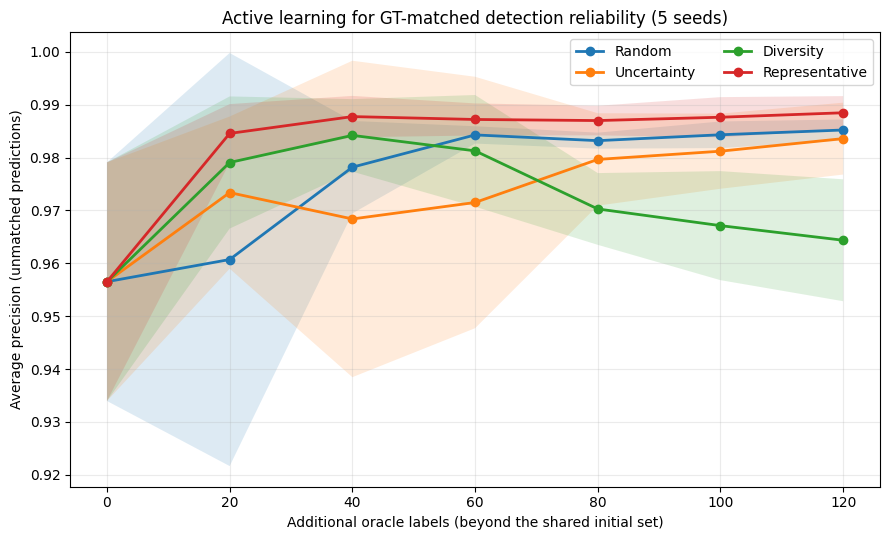

In [6]:
fig=plot_curves(all_runs,metric='average_precision',save=OUTPUT_DIR/'learning_curves.png')
display(fig)
plt.close(fig)


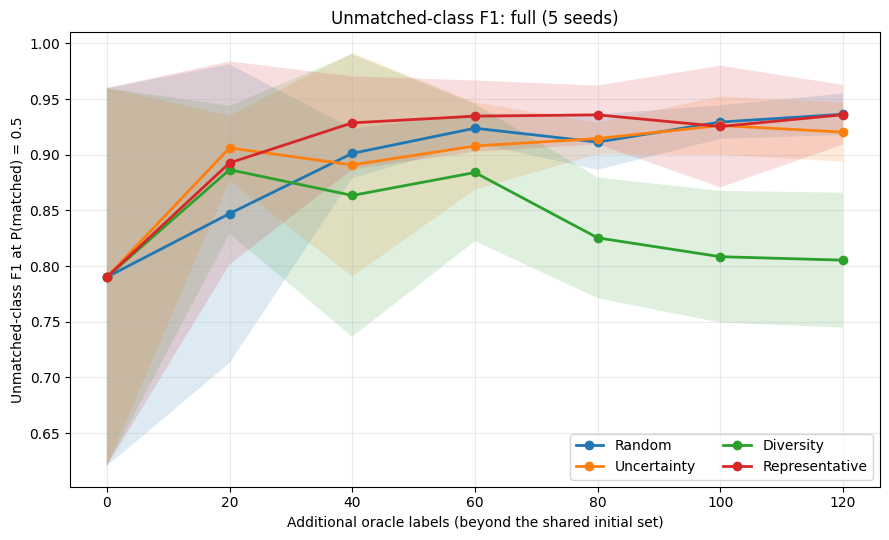

In [7]:
fig=plot_curves(all_runs,metric='positive_f1',save=OUTPUT_DIR/'learning_curves_f1.png')
fig.axes[0].set_ylabel('Unmatched-class F1 at P(matched) = 0.5')
fig.axes[0].set_title(f'Unmatched-class F1: {DATA_MODE} (5 seeds)')
fig.savefig(OUTPUT_DIR/'learning_curves_f1.png',dpi=180,bbox_inches='tight')
display(fig)
plt.close(fig)


## 7 · Results and comparison with random selection

### Full 947-frame results observed 

These numbers were copied from the **successful full-dataset terminal run** (`scripts/run_experiments.py --dataset data/real/repair_store_reliability.csv.gz --rounds 6 --batch-size 20`). They are **real experimental measurements**, not synthetic performance.

| Acquisition policy | Final mean unmatched AP | Sample SD | Range (five runs) |
|---|---:|---:|---:|
| **Representative** | **0.988467** | 0.003154 | 0.985129–0.993626 |
| Random | 0.985208 | 0.001989 | 0.982476–0.987533 |
| Uncertainty | 0.983580 | 0.006801 | 0.971526–0.988096 |
| Diversity | 0.964353 | 0.011531 | 0.951833–0.982573 |

**Interpretation from the full terminal results:** Representative is **+0.003259 AP (0.326 percentage points)** above random at the final annotation budget; uncertainty is **−0.001628 AP**, and diversity **−0.020855 AP**. Five seeds and the overlapping outcome ranges do not establish statistical superiority. The key result is that **Active Learning does not automatically beat random sampling**; the dataset and acquisition criterion matter. We must inspect the learning curves at earlier budgets as well.

**Unmatched-class prevalence** in the full held-out test set is **1,845/3,120 ≈ 0.5913**, which is the expected AP of a random ranking. The high learned AP means the chosen tabular features rank GT-unmatched predictions well *in this Repair Store temporal split*; it does **not** imply 98% detection accuracy, improve YOLO, or demonstrate better identity tracking.


In [8]:
final = final_table(all_runs).round(6)
final.index.name = 'strategy'
print(f'Final UNMATCHED-class AP at {20 + settings.rounds*settings.batch_size} labeled examples:')
display(final)
last=all_runs[all_runs['round']==settings.rounds]
per_seed=last.pivot(index='seed',columns='strategy',values='average_precision')
print('Per-seed final AP:')
display(per_seed.round(5))
paired=per_seed.sub(per_seed['random'],axis=0).drop(columns='random')
print('Paired improvements vs random (same seeds):')
display(paired.agg(['mean','std']).round(5))
# Budget-averaged AP is a secondary measure of label-efficiency, rather than final AP alone.
by_run = []
for (seed, policy), group in all_runs.groupby(['seed','strategy']):
    part = group.sort_values('new_labels')
    x = part['new_labels'].to_numpy(dtype=float)
    y = part['average_precision'].to_numpy(dtype=float)
    by_run.append({'seed':seed, 'strategy':policy, 'mean_curve_ap':float((np.trapezoid(y, x) if hasattr(np, "trapezoid") else np.trapz(y, x))/(x[-1]-x[0]))})
curve_auc = pd.DataFrame(by_run).groupby('strategy')['mean_curve_ap'].agg(['mean','std']).sort_values('mean',ascending=False)
print('Budget-averaged AP (trapezoidal integral of the learning curve):')
display(curve_auc.round(5))


Final UNMATCHED-class AP at 140 labeled examples:


,mean,std,min,max
strategy,,,,
representative,0.988467,0.003154,0.985129,0.993626
random,0.985208,0.001989,0.982476,0.987533
uncertainty,0.983580,0.006801,0.971526,0.988096
diversity,0.964353,0.011531,0.951833,0.982573


Per-seed final AP:


strategy,diversity,random,representative,uncertainty
seed,,,,
11,0.95954,0.98753,0.99363,0.98595
22,0.95183,0.98398,0.98727,0.98810
33,0.96703,0.98625,0.98513,0.98656
44,0.96079,0.98248,0.98861,0.98576
55,0.98257,0.98580,0.98769,0.97153


Paired improvements vs random (same seeds):


strategy,diversity,representative,uncertainty
mean,-0.02086,0.00326,-0.00163
std,0.01110,0.00306,0.00743


Budget-averaged AP (trapezoidal integral of the learning curve):


,mean,std
strategy,,
representative,0.98443,0.00405
random,0.97692,0.00811
uncertainty,0.97402,0.01356
diversity,0.97372,0.00520


## 8 · Sanity check: does tracking history help beyond detector confidence?

A crucial reference is a **non-learned YOLO-confidence baseline**: rank a detection as likely unmatched when `confidence` is low. Its test AP requires **zero labeled classifier examples**. If the 11-feature Active Learning classifier does not exceed this simple score, its added complexity may not be justified for practical use even if the four policy curves are internally reproducible. This is an *additional diagnostic*, not a fifth acquisition strategy, and it uses exactly the same fixed test partition.


In [9]:
test_part=data[data.split=='test']
prevalence=(test_part.label==0).mean()
confidence_ap=average_precision_score(1-test_part.label.to_numpy(),
                                      1-test_part.confidence.to_numpy())
best_policy=final.index[0]
print(f'DATA MODE: {DATA_MODE.upper()}')
print(f'Random ranking AP (unmatched prevalence): {prevalence:.5f}')
print(f'Confidence-only AP (unmatched score = 1-confidence): {confidence_ap:.5f}')
print(f'Final best mean AL AP ({best_policy}): {final.iloc[0]["mean"]:.5f}')
print(f'Best final mean AL - confidence-only AP: {final.iloc[0]["mean"]-confidence_ap:+.5f}')
print('This comparison does not isolate causal benefits of ByteTrack. A fixed-feature ablation is future work.')


DATA MODE: FULL
Random ranking AP (unmatched prevalence): 0.59135
Confidence-only AP (unmatched score = 1-confidence): 0.98882
Final best mean AL AP (representative): 0.98847
Best final mean AL - confidence-only AP: -0.00035
This comparison does not isolate causal benefits of ByteTrack. A fixed-feature ablation is future work.


## 9. Discussion and Conclusion

### Comparison of Active Learning Strategies

The four Active Learning strategies were evaluated on the full 947-frame Repair Store dataset using six acquisition rounds and five random seeds. Each strategy used the same Logistic Regression classifier, initial labeling budget, and held-out test set.

**Representative sampling achieved the highest final Average Precision (AP) of 0.9885**, followed by Random (0.9852), Uncertainty (0.9836), and Diversity (0.9644).

Representative sampling performed slightly better than Random, suggesting that selecting examples that represent the overall data distribution can be useful. However, the improvement was small.

Uncertainty sampling achieved performance similar to Random but showed greater variation between repetitions. Diversity sampling initially improved but declined in later rounds, potentially because it selected unusual examples that were less helpful for classifying typical detections.

These explanations are possible interpretations rather than confirmed causes. The learning curves also show that **adding more labeled examples does not always improve classification performance**.

### Interpretation of the Results

All strategies achieved relatively high AP scores, even with a small number of labeled examples. This suggests that features such as YOLO confidence and bounding-box geometry may already provide useful information for distinguishing matched and unmatched detections.

However, the experiment uses training and testing frames from the same Repair Store recording. Therefore, the results may not generalize equally well to different scenes or camera environments.

Importantly, AP measures how effectively the classifier ranks unmatched detections. It does not represent the percentage of correctly tracked people or the accuracy of ByteTrack identities.

### Limitations

The reference labels are generated by matching predicted and ground-truth oriented bounding boxes using Hungarian assignment and an IoU threshold of 0.50. Consequently, unmatched detections may include poorly localized boxes or duplicate predictions, rather than only false detections. Completely missed persons are not represented as classifier samples.

The classifier evaluates individual detections rather than identity consistency across frames. Additionally, all five repetitions use the same video sequence, and the simulated annotator reveals existing ground-truth-derived labels instead of collecting real human feedback.

This deliverable does not involve correcting bounding boxes, fine-tuning YOLO, or improving ByteTrack directly.

### Conclusion and Future Work

The experiment demonstrates that **Active Learning strategies differ in how effectively they use a limited annotation budget**. Representative sampling achieved the best overall results, although its advantage over Random sampling was small. Uncertainty sampling was competitive, while Diversity sampling performed worse.

For future deliverables, we plan to introduce real human annotation, allowing annotators to review and correct selected detections. These annotations can be used to retrain the reliability classifier and potentially fine-tune YOLO.

We may then rerun ByteTrack to investigate whether improved detections also improve tracking performance. Evaluation on additional WEPDTOF scenes would help determine whether the findings generalize beyond the Repair Store recording.

**Overall, Deliverable 1 establishes an Active Learning framework for identifying unreliable person detections with limited labeled data. It does not yet demonstrate improvements in identity-preserving tracking.**


In [10]:
print('FINAL NOTEBOOK STATUS:', 'READY FOR FULL-RESULT SAVE' if DATA_MODE=='full' else 'PILOT ONLY — NOT READY FOR FINAL GITHUB SUBMISSION')
print('Plots and CSVs saved to:', OUTPUT_DIR)
print('Remember to SAVE this notebook so the executed full-data outputs become visible on GitHub.')


FINAL NOTEBOOK STATUS: READY FOR FULL-RESULT SAVE
Plots and CSVs saved to: /home/mnoor1/person_tracking/Wepdtof/hitl2026-tracking-reliability/results/full
Remember to SAVE this notebook so the executed full-data outputs become visible on GitHub.
